In [1]:
import sys
print(sys.executable)

/Users/aymanbelbachir/covid-ct-classifier/.venv/bin/python3


In [2]:
import random
import time
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch import nn, optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from tqdm.auto import tqdm

Matplotlib is building the font cache; this may take a moment.


In [6]:
DATA_ROOT = Path("data")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
IMG_SIZE= 224
BATCH_SIZE= 16
EPOCHS= 25
Lr = 1e-4
SEED =42

device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
print("Pytorch version", torch.__version__,"|device", device)

Pytorch version 2.14.1 |device mps


In [10]:
dataset= datasets.ImageFolder(DATA_ROOT)
classes = dataset.classes
print("Classes :", dataset.class_to_idx)
counts = Counter(dataset.targets)
for i, name in enumerate(classes):
    print(f"{name:5s} {counts[i]:6,} images")
print(f"Total : {len(dataset):,} images")
    

Classes : {'NiCT': 0, 'nCT': 1, 'pCT': 2}
NiCT   5,705 images
nCT    9,979 images
pCT    4,001 images
Total : 19,685 images


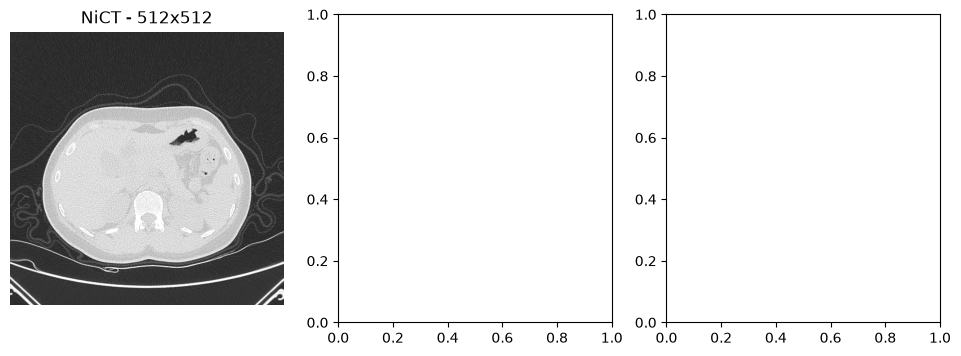

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, name in enumerate(classes):
    idx = random.choice([j for j, t in enumerate(dataset.targets) if t == i])
    path, _ = dataset.samples[idx]
    img = Image.open(path)
    axes[i].imshow(img, cmap="gray")
    axes[i].set_title(f"{name} - {img.size[0]}x{img.size[1]}")
    axes[i].axis("off")
    plt.show()

In [22]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])




In [23]:
path, label = dataset.samples[0]
print("Image :", path, "| classe :", classes[label])

image = Image.open(path).convert("RGB")
x = eval_transform(image)
print("Shape :", x.shape)
print("Min / max :", x.min().item(), x.max().item())

a = train_transform(image)
b = train_transform(image)
print("Train : identiques ?", torch.equal(a, b))

c = eval_transform(image)
d = eval_transform(image)
print("Eval : identiques ?", torch.equal(c, d))

Image : data/NiCT/NiCT1.jpg | classe : NiCT
Shape : torch.Size([3, 224, 224])
Min / max : -1.432913899421692 2.640000104904175
Train : identiques ? False
Eval : identiques ? True


In [24]:
rng = random.Random(SEED)

by_class = {i: [] for i in range(len(classes))}
for idx, label in enumerate(dataset.targets):
    by_class[label].append(idx)

train_idx, val_idx, test_idx = [], [], []
for label, idxs in by_class.items():
    rng.shuffle(idxs)
    n_train = int(0.70 * len(idxs))
    n_val = int(0.15 * len(idxs))
    train_idx += idxs[:n_train]
    val_idx += idxs[n_train:n_train + n_val]
    test_idx += idxs[n_train + n_val:]

print(f"Train : {len(train_idx):,} | Validation : {len(val_idx):,} | Test : {len(test_idx):,}")

Train : 13,778 | Validation : 2,951 | Test : 2,956


In [25]:
train_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=train_transform), train_idx)
val_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=eval_transform), val_idx)
test_ds = Subset(datasets.ImageFolder(DATA_ROOT, transform=eval_transform), test_idx)

loader_args = dict(batch_size=BATCH_SIZE, num_workers=4, persistent_workers=True)
train_loader = DataLoader(train_ds, shuffle=True, **loader_args)
val_loader = DataLoader(val_ds, shuffle=False, **loader_args)
test_loader = DataLoader(test_ds, shuffle=False, **loader_args)

images, labels = next(iter(train_loader))
print("Batch d'images :", images.shape)
print("Labels         :", labels)

Batch d'images : torch.Size([16, 3, 224, 224])
Labels         : tensor([0, 2, 1, 1, 2, 1, 1, 1, 1, 0, 0, 2, 2, 2, 2, 2])


In [26]:
head = nn.Sequential(
    nn.Linear(960, 1280),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(1280, len(classes)),
)
print(head)

Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=1280, out_features=3, bias=True)
)


In [27]:
model = models.mobilenet_v3_large(weights="DEFAULT")
print("Tête d'origine :")
print(model.classifier)

model.classifier = head
model = model.to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Paramètres entraînables : {n_params:,}")

Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /Users/aymanbelbachir/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 21.1M/21.1M [00:03<00:00, 5.78MB/s]


Tête d'origine :
Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)
Paramètres entraînables : 4,205,875


In [28]:
model.eval()
with torch.no_grad():
    outputs = model(images.to(device))

print("Sortie :", outputs.shape)
print("Logits (3 premières images) :")
print(outputs[:3])
print("Probabilités (3 premières images) :")
print(torch.softmax(outputs, dim=1)[:3])

Sortie : torch.Size([16, 3])
Logits (3 premières images) :
tensor([[-0.0095, -0.1206,  0.0861],
        [-0.2437,  0.0429,  0.0331],
        [-0.2868,  0.0250,  0.1199]], device='mps:0')
Probabilités (3 premières images) :
tensor([[0.3339, 0.2988, 0.3674],
        [0.2739, 0.3648, 0.3613],
        [0.2585, 0.3531, 0.3883]], device='mps:0')
